# Tutorial 3: S2 simulation

In tutorial 2 we followed the photons of the S1. Now we follow the **electrons**. They drift upwards in the drift field, are extracted from the liquid into the gas, and produce a second, larger light signal there by **electroluminescence**: the **S2**.

ember simulates the S2 with five plugins, ported from fuse:

```
microphysics_summary
  └─ ElectronDrift          → drifted_electrons        how many electrons reach the liquid surface, and when?
  └─ ElectronPropagation    → electrons_at_interface   time and position of every single electron at the surface
  └─ ElectronExtraction     → extracted_electrons      which electrons are extracted into the gas?
  └─ SecondaryScintillation → s2_photons               how many photons does each electron produce?
                              s2_photons_sum           ... and how many per interaction?
  └─ S2PhotonPropagation    → propagated_s2_photons    which PMT, at what time, with which gain?
```

The number of rows changes along the chain:

| Data type | One row per | Data kind |
|---|---|---|
| `drifted_electrons`, `s2_photons_sum` | interaction | `interactions_in_roi` |
| `electrons_at_interface`, `extracted_electrons`, `s2_photons` | electron | `individual_electrons` |
| `propagated_s2_photons` | detected photon | `s2_photons` |

The geometry of the top of the TPC (z = 0 is the gate):

```
  z_top_pmts      ═══════════  top PMT array
                     gas
  z_anode         ───────────  anode            ┐
                     gas                        │ electroluminescence (gas gap)
  z_liquid_level  ~~~~~~~~~~~  liquid surface   ┘ ← electrons are extracted here
                     liquid
  z_gate = 0      ───────────  gate
                     liquid      ↑ electrons drift up in the drift field
  z_cathode       ───────────  cathode
```

The S2 branch needs several maps. ember ships simple dummy versions in `ember/dummy_maps`; the notebooks in `map_generators/` explain how they are made.

| Input | What it describes | Used by |
|---|---|---|
| drift map `field_dependencies_dummy.json` | average drift velocity to the gate and diffusion constants as a function of $(r, z)$ | `ElectronDrift`, `ElectronPropagation` |
| survival map `electron_survival_below_cathode.json` | probability that an electron reaches the surface | `ElectronDrift` |
| S2 correction map `s2_correction_map_dummy.json` | relative S2 light yield $c(x, y)$ | `SecondaryScintillation` |
| S2 pattern map `s2_pattern_map_dummy.pkl` | which PMT sees the S2 light of an electron extracted at $(x, y)$ | `S2PhotonPropagation` |
| luminescence timing map `s2_luminescence_timing_dummy.json` | when the photons are emitted on the way to the anode | `S2PhotonPropagation` |
| S2 optical timing map `s2_optical_propagation_dummy.json` | how long the photons travel to the top or bottom array | `S2PhotonPropagation` |
| SPE spectra and gains | as for the S1 | `S2PhotonPropagation` |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import strax

import ember

## 1. Simulate the microphysics

We reuse the 40 keV betas from tutorial 1 with the same run id as in tutorial 2. If you have not run tutorial 1, run its section 2 first to create `beta_40keV.csv`.

**One run id per CSV file.** The name of the input file is not part of the lineage (as in fuse). If you simulate a second CSV file with the same run id into the same storage folder, strax finds the data of the first file and loads it instead. Use a new run id (or a new output folder) for every input file.

In [2]:
st = ember.ember_context(output_folder="./strax_data")
st.set_config({"input_file": "beta_40keV.csv"})

run_id = "000001"
microphysics_summary = st.get_array(run_id, "microphysics_summary")
print("Interactions:", len(microphysics_summary))
print("Mean number of electrons:", microphysics_summary["electrons"].mean())

Loading microphysics_summary: |██████████| 100.00 % [00:00<00:00], #1 (0.00 s). 49.7 MB/s

Interactions: 1000
Mean number of electrons: 778.313


We read a few detector values from `detector.yaml` with the `detector://` protocol. We need them for the plots:

In [3]:
z_cathode = strax.URLConfig.evaluate_dry("detector://z_cathode")
z_gate = strax.URLConfig.evaluate_dry("detector://z_gate")
z_liquid_level = strax.URLConfig.evaluate_dry("detector://z_liquid_level")
z_anode = strax.URLConfig.evaluate_dry("detector://z_anode")
tpc_radius = strax.URLConfig.evaluate_dry("detector://tpc_radius")
n_top_pmts = strax.URLConfig.evaluate_dry("detector://n_top_pmts")
n_tpc_pmts = strax.URLConfig.evaluate_dry("detector://n_tpc_pmts")

electron_lifetime = strax.URLConfig.evaluate_dry("detector://electron_lifetime_liquid")
drift_time_gate = strax.URLConfig.evaluate_dry("detector://drift_time_gate")
extraction_efficiency = strax.URLConfig.evaluate_dry("detector://electron_extraction_efficiency")
g2 = strax.URLConfig.evaluate_dry("detector://g2")
p_double_pe = strax.URLConfig.evaluate_dry("detector://p_double_pe_emission")

print("Gate to liquid surface:", z_liquid_level - z_gate, "cm")
print("Gas gap (liquid surface to anode):", z_anode - z_liquid_level, "cm")
print("Electron lifetime:", electron_lifetime / 1e6, "ms")

Gate to liquid surface: 0.5116 cm
Gas gap (liquid surface to anode): 0.29879999999999995 cm
Electron lifetime: 20.0 ms


## 2. `ElectronDrift`: how many electrons reach the surface, and when?

For every interaction with $N_e$ electrons at $(x, y, z)$ the plugin does four things:

1. **Charge-insensitive regions.** Electrons below the cathode drift down, not up. They are removed with the survival map: $N' \sim \mathrm{Binomial}(N_e, p_\mathrm{surv}(r, z))$.
2. **Mean drift time.** Below the gate the electrons drift with the average velocity $\bar v(r, z)$ from the drift map, above the gate (in the much stronger extraction field) they need the fixed time $t_\mathrm{gate}$:
   $$t_\mathrm{drift} = \frac{z_\mathrm{gate} - z}{\bar v(r, z)} + t_\mathrm{gate}.$$
3. **Drift time spread.** On their way the electrons diffuse along the drift direction (longitudinal diffusion constant $D_L$). The arrival times spread by
   $$\sigma_t^2 = \frac{2 D_L\, t_\mathrm{below}}{\bar v^2} + \frac{2 D_{L,\mathrm{gate}}\, t_\mathrm{gate}}{v_\mathrm{gate}^2}.$$
4. **Electron lifetime.** Electronegative impurities capture electrons on the way: $N_\mathrm{interface} \sim \mathrm{Binomial}(N', e^{-t_\mathrm{drift}/\tau_e})$.

ember does not simulate field distortion: the observed position (`x_obs`, `y_obs`, `z_obs`) is the true position.

### The drift map

The drift map stores, as a function of $(r, z)$, the **average** drift velocity from the interaction up to the gate and the average diffusion constants. It is made in `map_generators/dummy_field_maps.ipynb` from the electric field map and NEST. ember's dummy field is a constant 23 V/cm, so all values are constant inside the TPC:

Axes: ['r', 'z']
Maps: ['diffusion_longitudinal_map', 'diffusion_transverse_map', 'drift_speed_map']


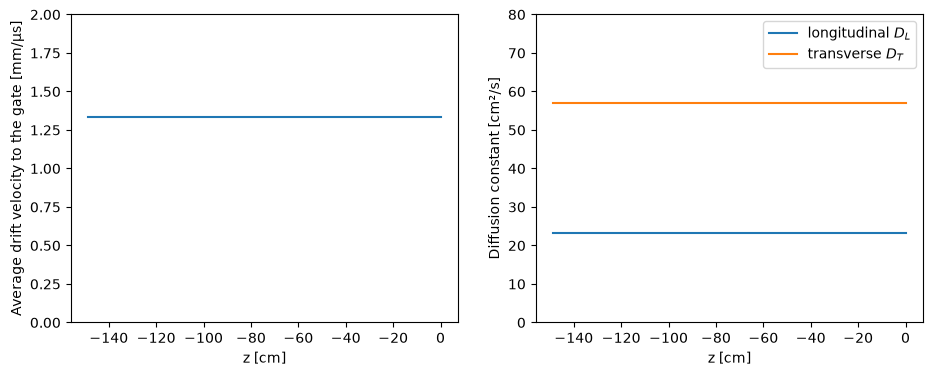

In [4]:
drift_map = strax.URLConfig.evaluate_dry("ember_map://field_dependencies_dummy.json?method=linear")
print("Axes:", drift_map.axis_names)
print("Maps:", drift_map.map_names)

z_values = np.linspace(z_cathode, z_gate, 100)
positions_r_z = np.column_stack([np.zeros(100), z_values])

drift_velocity = drift_map(positions_r_z, map_name="drift_speed_map")
diffusion_longitudinal = drift_map(positions_r_z, map_name="diffusion_longitudinal_map")
diffusion_transverse = drift_map(positions_r_z, map_name="diffusion_transverse_map")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(z_values, drift_velocity * 1e4)
axes[0].set_xlabel("z [cm]")
axes[0].set_ylabel("Average drift velocity to the gate [mm/µs]")
axes[0].set_ylim(0, 2)
axes[1].plot(z_values, diffusion_longitudinal * 1e9, label="longitudinal $D_L$")
axes[1].plot(z_values, diffusion_transverse * 1e9, label="transverse $D_T$")
axes[1].set_xlabel("z [cm]")
axes[1].set_ylabel("Diffusion constant [cm²/s]")
axes[1].set_ylim(0, 80)
axes[1].legend()
plt.show()

With a real, non-uniform field (e.g. from a COMSOL simulation of your electrodes) these curves change with $r$ and $z$. Only the map has to be replaced, the plugins stay the same. (ember does not consider the drift along bended field lines).

### Settings

| Option | Default | Meaning |
|---|---|---|
| `field_dependencies_map` | `ember_map://field_dependencies_dummy.json?method=linear` | drift map (maps `drift_speed_map` [cm/ns], `diffusion_longitudinal_map`, `diffusion_transverse_map` [cm²/ns]) |
| `survival_probability_map` | `ember_map://electron_survival_below_cathode.json?method=nearest` | $p_\mathrm{surv}(r, z)$ |
| `electron_lifetime_liquid` | 20 ms (in ns) | $\tau_e$; 0 or less switches the lifetime off |
| `drift_time_gate` | 1984 ns | $t_\mathrm{gate}$, from NEST at the extraction field |
| `diffusion_constant_longitudinal_gate` | 9.1e-9 cm²/ns | $D_{L,\mathrm{gate}}$ |
| `z_gate`, `z_liquid_level` | `detector://…` | geometry |

In [5]:
st.show_config("drifted_electrons")

,option,default,current,applies_to,help
0,debug,False,<OMITTED>,"(drifted_electrons,)",Show debug informations
1,deterministic_seed,True,<OMITTED>,"(drifted_electrons,)","Set the random seed from lineage and run_id, o..."
2,user_defined_random_seed,None,<OMITTED>,"(drifted_electrons,)",Define the random seed manually. You need to s...
3,field_dependencies_map,ember_map://field_dependencies_dummy.json?meth...,<OMITTED>,"(drifted_electrons,)","(r, z) map with the average drift velocity to ..."
4,survival_probability_map,ember_map://electron_survival_below_cathode.js...,<OMITTED>,"(drifted_electrons,)","(r, z) map of the probability that an electron..."
5,electron_lifetime_liquid,detector://electron_lifetime_liquid,<OMITTED>,"(drifted_electrons,)",Electron lifetime in liquid xenon [ns]; 0 or l...
6,drift_time_gate,detector://drift_time_gate,<OMITTED>,"(drifted_electrons,)",Drift time from the gate to the liquid surface...
7,diffusion_constant_longitudinal_gate,detector://diffusion_constant_longitudinal_gate,<OMITTED>,"(drifted_electrons,)",Longitudinal diffusion constant between gate a...
8,z_gate,detector://z_gate,<OMITTED>,"(drifted_electrons,)",z position of the gate [cm]
9,z_liquid_level,detector://z_liquid_level,<OMITTED>,"(drifted_electrons,)",z position of the liquid surface [cm]


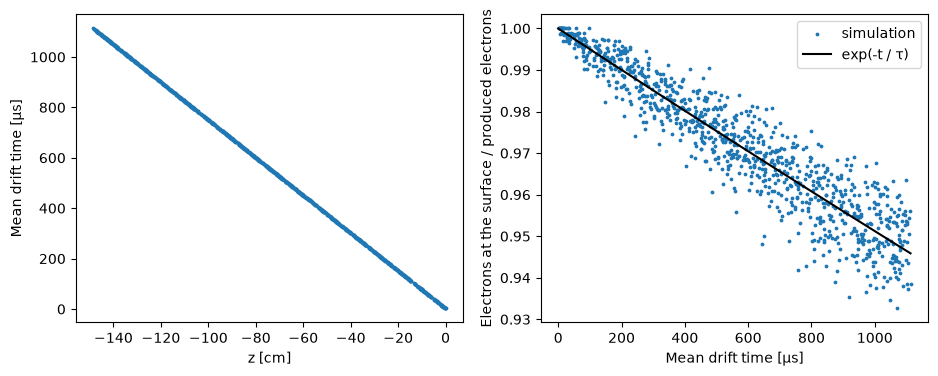

In [6]:
drifted = st.get_array(run_id, ["microphysics_summary", "drifted_electrons"])

drift_time_us = drifted["drift_time_mean"] / 1000
surviving_fraction = drifted["n_electron_interface"] / drifted["electrons"]

time_curve_us = np.linspace(0, drift_time_us.max(), 100)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(drifted["z"], drift_time_us, s=3)
axes[0].set_xlabel("z [cm]")
axes[0].set_ylabel("Mean drift time [µs]")
axes[1].scatter(drift_time_us, surviving_fraction, s=3, label="simulation")
axes[1].plot(time_curve_us, np.exp(-time_curve_us * 1000 / electron_lifetime), color="black", label="exp(-t / τ)")
axes[1].set_xlabel("Mean drift time [µs]")
axes[1].set_ylabel("Electrons at the surface / produced electrons")
axes[1].legend()
plt.show()

With $\tau_e = 20$ ms only a few percent of the electrons are lost even from the bottom of the TPC. A worse purity, e.g. $\tau_e = 1$ ms, removes most electrons of deep interactions. Changing an option changes the lineage, so strax simulates the data again:

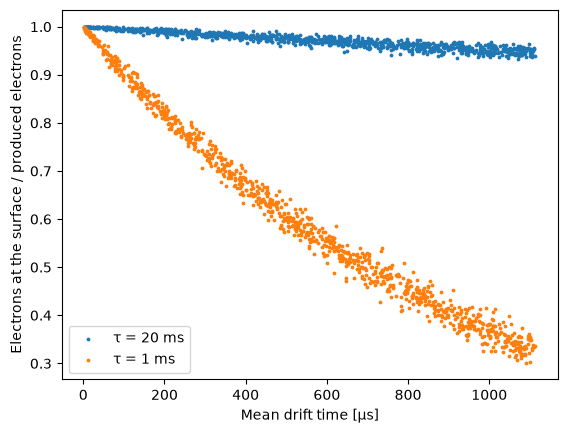

In [7]:
st_short_lifetime = st.new_context()
st_short_lifetime.set_config({"electron_lifetime_liquid": 1e6})
drifted_short = st_short_lifetime.get_array(run_id, ["microphysics_summary", "drifted_electrons"])

plt.scatter(drift_time_us, surviving_fraction, s=3, label="τ = 20 ms")
plt.scatter(drifted_short["drift_time_mean"] / 1000, drifted_short["n_electron_interface"] / drifted_short["electrons"], s=3, label="τ = 1 ms")
plt.xlabel("Mean drift time [µs]")
plt.ylabel("Electrons at the surface / produced electrons")
plt.legend()
plt.show()

## 3. `ElectronPropagation`: every single electron at the surface

Now each interaction is split into its $N_\mathrm{interface}$ electrons. Every electron gets its own

* **arrival time** $t \sim \mathcal{N}(t_\mathrm{drift}, \sigma_t)$ (longitudinal diffusion),
* **position** at the surface $(x + \Delta x,\; y + \Delta y)$ with $\Delta x, \Delta y \sim \mathcal{N}\left(0, \sqrt{2 D_T t}\right)$ (transverse diffusion).

The output is sorted by time, like all strax data. The only option is the drift map (for $D_T$).

Let us compare the electrons of the shallowest and of the deepest interaction:

In [8]:
electrons = st.get_array(run_id, "electrons_at_interface")
print("Electrons at the surface:", len(electrons))
print("Sum of n_electron_interface:", drifted["n_electron_interface"].sum())

shallow = drifted[np.argmax(drifted["z"])]
deep = drifted[np.argmin(drifted["z"])]
shallow_electrons = electrons[electrons["cluster_id"] == shallow["cluster_id"]]
deep_electrons = electrons[electrons["cluster_id"] == deep["cluster_id"]]

print(f"Shallow interaction: z = {shallow['z']:.2f} cm, {len(shallow_electrons)} electrons")
print(f"Deep interaction:    z = {deep['z']:.1f} cm, {len(deep_electrons)} electrons")

Loading electrons_at_interface: |██████████| 100.00 % [00:00<00:00], #1 (0.02 s). 1010.6 MB/s

Electrons at the surface: 756562
Sum of n_electron_interface: 756562
Shallow interaction: z = -0.03 cm, 710 electrons
Deep interaction:    z = -148.5 cm, 991 electrons


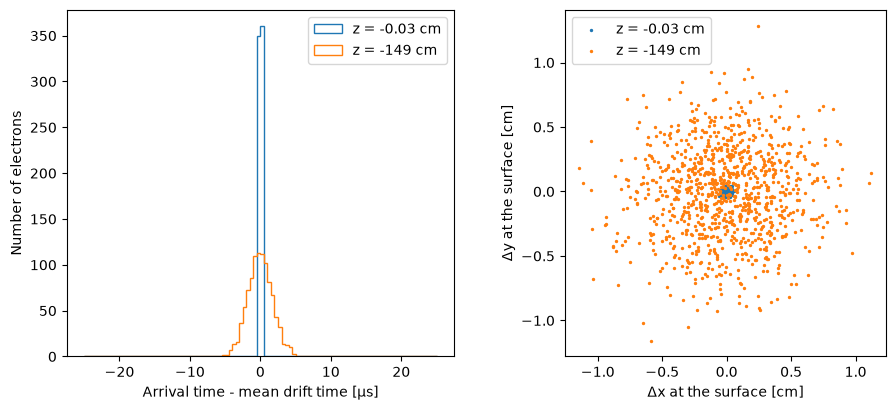

Deep interaction: σ_t = 1.70 µs (from drifted_electrons), measured 1.74 µs
Deep interaction: σ_xy = 0.36 cm expected, measured 0.37 cm


In [9]:
shallow_delay_us = (shallow_electrons["time"] - shallow["time"] - shallow["drift_time_mean"]) / 1000
deep_delay_us = (deep_electrons["time"] - deep["time"] - deep["drift_time_mean"]) / 1000

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
bins = np.linspace(-25, 25, 101)
axes[0].hist(shallow_delay_us, bins=bins, histtype="step", label=f"z = {shallow['z']:.2f} cm")
axes[0].hist(deep_delay_us, bins=bins, histtype="step", label=f"z = {deep['z']:.0f} cm")
axes[0].set_xlabel("Arrival time - mean drift time [µs]")
axes[0].set_ylabel("Number of electrons")
axes[0].legend()

axes[1].scatter(shallow_electrons["x_interface"] - shallow["x"], shallow_electrons["y_interface"] - shallow["y"], s=2, label=f"z = {shallow['z']:.2f} cm")
axes[1].scatter(deep_electrons["x_interface"] - deep["x"], deep_electrons["y_interface"] - deep["y"], s=2, label=f"z = {deep['z']:.0f} cm")
axes[1].set_xlabel("Δx at the surface [cm]")
axes[1].set_ylabel("Δy at the surface [cm]")
axes[1].set_aspect("equal")
axes[1].legend()
plt.show()

print(f"Deep interaction: σ_t = {deep['drift_time_spread'] / 1000:.2f} µs (from drifted_electrons), measured {np.std(deep_delay_us):.2f} µs")
expected_sigma_xy = np.sqrt(2 * diffusion_transverse[0] * deep["drift_time_mean"])
print(f"Deep interaction: σ_xy = {expected_sigma_xy:.2f} cm expected, measured {np.std(deep_electrons['x_interface'] - deep['x']):.2f} cm")

Electrons from deep interactions arrive spread over several µs and a few mm. This is why S2s from the bottom of the TPC are wider than S2s from the top: the S2 width is a measure of the depth.

## 4. `ElectronExtraction`: into the gas

At the liquid surface each electron is extracted into the gas with the probability $\varepsilon_\mathrm{ext}$ (one random draw per electron). Electrons are not extracted at once: they wait on average `electron_trapping_time` at the surface, so an exponential delay is added.

| Option | Default | Meaning |
|---|---|---|
| `electron_extraction_yield` | `detector://electron_extraction_efficiency` (0.8) | $\varepsilon_\mathrm{ext}$ |
| `electron_trapping_time` | 140 ns | mean delay at the surface |

In [10]:
extracted = st.get_array(run_id, ["extracted_electrons", "s2_photons"])
print("Extracted electrons:", len(extracted))
print("Extracted fraction:", len(extracted) / len(electrons), "(ε_ext =", extraction_efficiency, ")")

Extracted electrons: 604597
Extracted fraction: 0.7991374137215457 (ε_ext = 0.8 )


## 5. `SecondaryScintillation`: photons per electron

In the gas between the liquid surface and the anode the field is strong enough that the electron excites xenon atoms, which emit VUV light. Each extracted electron produces a number of **detected** photons drawn from a Poisson distribution:

$$N_\gamma \sim \mathrm{Poisson}\left(\frac{c(x, y)\; g_\mathrm{SE}}{1 + p_\mathrm{DPE}}\right), \qquad g_\mathrm{SE} = \frac{g_2}{\varepsilon_\mathrm{ext}}.$$

* $g_\mathrm{SE}$ is the **single electron gain**: the mean S2 area of one extracted electron in PE. ember computes it from $g_2$ and $\varepsilon_\mathrm{ext}$, so $g_2$ (PE per electron that reaches the surface) stays the single number to tune.
* $c(x, y)$ is the relative S2 light yield (correction map, mean 1). In a real detector it describes e.g. a sagging anode or a tilted liquid surface. ember's dummy map is constant 1.
* As for the S1, the second PE of a double photoelectron emission is added later, hence the division by $1 + p_\mathrm{DPE}$.

Only photons that reach a PMT are simulated; the lost photons are already part of $g_\mathrm{SE}$.

The plugin writes two outputs: `s2_photons` (one row per extracted electron, aligned with `extracted_electrons`) and `s2_photons_sum` (one row per interaction).

| Option | Default | Meaning |
|---|---|---|
| `g2` | `detector://g2` (30 PE) | S2 PE per electron at the liquid surface |
| `electron_extraction_yield` | 0.8 | same option as in `ElectronExtraction` |
| `s2_correction_map` | `ember_map://s2_correction_map_dummy.json?method=linear` | $c(x, y)$ |
| `p_double_pe_emission` | 0.219 | $p_\mathrm{DPE}$ |

Single electron gain: 37.5 PE, mean number of photons per electron: 30.8


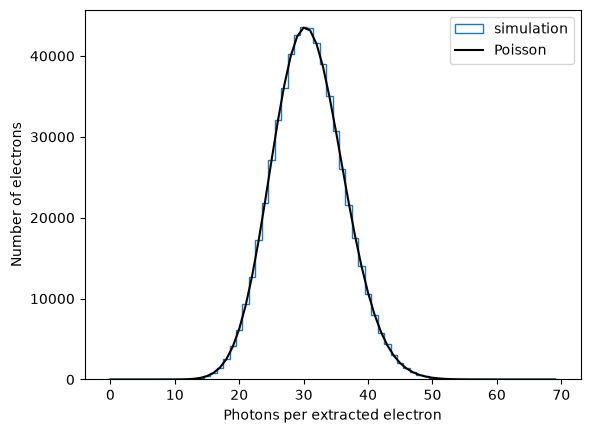

In [11]:
from scipy.stats import poisson

single_electron_gain = g2 / extraction_efficiency
mean_photons = single_electron_gain / (1 + p_double_pe)
print(f"Single electron gain: {single_electron_gain:.1f} PE, mean number of photons per electron: {mean_photons:.1f}")

counts = np.arange(0, 70)
plt.hist(extracted["n_s2_photons"], bins=np.arange(-0.5, 70.5), histtype="step", label="simulation")
plt.plot(counts, poisson.pmf(counts, mean_photons) * len(extracted), color="black", label="Poisson")
plt.xlabel("Photons per extracted electron")
plt.ylabel("Number of electrons")
plt.legend()
plt.show()

Per interaction, the expected S2 area in PE is the number of electrons at the surface times $g_2$ (the extraction efficiency cancels):

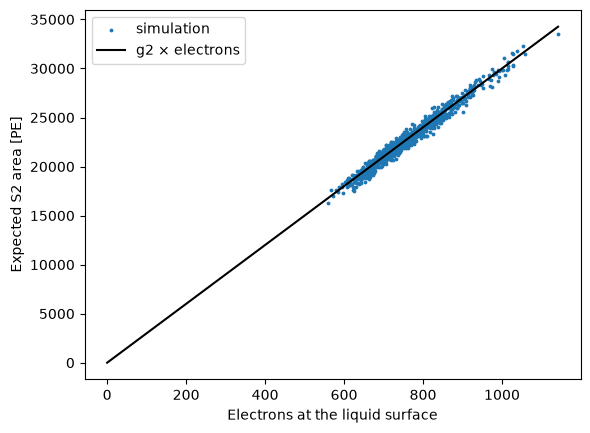

In [12]:
s2_sum = st.get_array(run_id, ["drifted_electrons", "s2_photons_sum"])
s2_area_pe = s2_sum["sum_s2_photons"] * (1 + p_double_pe)

electrons_curve = np.linspace(0, s2_sum["n_electron_interface"].max(), 10)
plt.scatter(s2_sum["n_electron_interface"], s2_area_pe, s=3, label="simulation")
plt.plot(electrons_curve, g2 * electrons_curve, color="black", label="g2 × electrons")
plt.xlabel("Electrons at the liquid surface")
plt.ylabel("Expected S2 area [PE]")
plt.legend()
plt.show()

The S2 size scales with $g_2$. Halve it:

In [13]:
st_small_g2 = st.new_context()
st_small_g2.set_config({"g2": 15.0})
s2_sum_small = st_small_g2.get_array(run_id, ["drifted_electrons", "s2_photons_sum"])

print("Mean S2 PE per electron at the surface, g2 = 30:", np.sum(s2_area_pe) / np.sum(s2_sum["n_electron_interface"]))
print("Mean S2 PE per electron at the surface, g2 = 15:", np.sum(s2_sum_small["sum_s2_photons"] * (1 + p_double_pe)) / np.sum(s2_sum_small["n_electron_interface"]))

Mean S2 PE per electron at the surface, g2 = 30: 29.95812835167508
Mean S2 PE per electron at the surface, g2 = 15: 14.980490119778683


## 6. `S2PhotonPropagation`: channel, time and gain of every photon

This plugin turns the photon numbers of the electrons into individual photons, like `S1PhotonPropagation` for the S1.

### 6.1 Channel

The channel is drawn from the **S2 pattern map** $P(c \mid x, y)$ at the position where the electron was extracted. The map sums to 1 over all channels and already contains the split between the top and the bottom array (AFT). Switched-off PMTs are removed and the other channels renormalized.

### 6.2 Arrival time

The arrival time is the extraction time of the electron plus

1. **Luminescence delay.** The photons are emitted while the electron drifts through the gas gap to the anode, which takes several 100 ns. The map gives the emission time as an inverse cumulative distribution in $u \in [0, 1]$, as the S1 timing map.
2. **Excimer decay.** The light comes from excited xenon dimers in the gas: singlet (5.9 ns, fraction 0.35) or triplet (100 ns).
3. **Optical delay** to the top or bottom array (map from ember's optical toy Monte Carlo).
4. **PMT transit time**, as for the S1.

### 6.3 Gain

As for the S1: PMT gain × SPE factor, two PE with probability $p_\mathrm{DPE}$.

### Settings

| Option | Default | Meaning |
|---|---|---|
| `s2_pattern_map` | `ember_map://s2_pattern_map_dummy.pkl?method=linear` | $P(c \mid x, y)$ |
| `s2_luminescence_timing_map` | `ember_map://s2_luminescence_timing_dummy.json?method=linear` | emission time after the extraction, axis `u` |
| `s2_optical_propagation_spline` | `ember_map://s2_optical_propagation_dummy.json?method=linear` | optical delay, axis `u`, maps `top` and `bottom` |
| `singlet_fraction_gas`, `singlet_lifetime_gas`, `triplet_lifetime_gas` | 0.35, 5.88 ns, 100.1 ns | excimer decay |
| `photon_area_distribution`, `gain_model_mc`, `p_double_pe_emission`, `pmt_transit_time_*` | as for the S1 | gains and transit time |
| `propagated_s2_photons_file_size_target` | 300 MB | larger outputs are split into several chunks (not tracked) |
| `min_electron_gap_length_for_splitting` | 2 ms | chunks are only split between electrons that are this far apart (not tracked) |

In [14]:
s2_photons = st.get_array(run_id, "propagated_s2_photons")
print("Number of photons:", len(s2_photons))
print("Sum of n_s2_photons:", extracted["n_s2_photons"].sum())
print("AFT of all photons:", np.mean(s2_photons["channel"] < n_top_pmts))
s2_photons[:5]

Loading propagated_s2_photons: |██████████| 100.00 % [00:00<00:00], #2 (0.17 s). 1302.0 MB/s


Number of photons: 18593258
Sum of n_s2_photons: 18593258
AFT of all photons: 0.7998795584937293


array([(169, False, 3359992, 1, 2, 3091900917, 3091900917),
       (169, False, 2845707, 1, 2, 3091900923, 3091900923),
       (169, False, 2399994, 1, 2, 3091900967, 3091900967),
       (211, False, 1439996, 1, 2, 3091900985, 3091900985),
       (211, False, 2811422, 1, 2, 3091901020, 3091901020)],
      dtype=[(('PMT channel of the photon', 'channel'), '<i2'), (('Photon creates a double photo-electron emission', 'dpe'), '?'), (('Sampled PMT gain for the photon', 'photon_gain'), '<i4'), (('ID of the cluster creating the photon', 'cluster_id'), '<i4'), (('Type of the photon. S1 (1), S2 (2) or PMT AP (0)', 'photon_type'), 'i1'), (('Start time since unix epoch [ns]', 'time'), '<i8'), (('Exclusive end time since unix epoch [ns]', 'endtime'), '<i8')])

### The hit pattern on the top array

The S2 light is produced just below the top array, so most of it lands in the PMTs right above the extraction point. Plot the photons of one interaction on the PMT positions of the dummy layout:

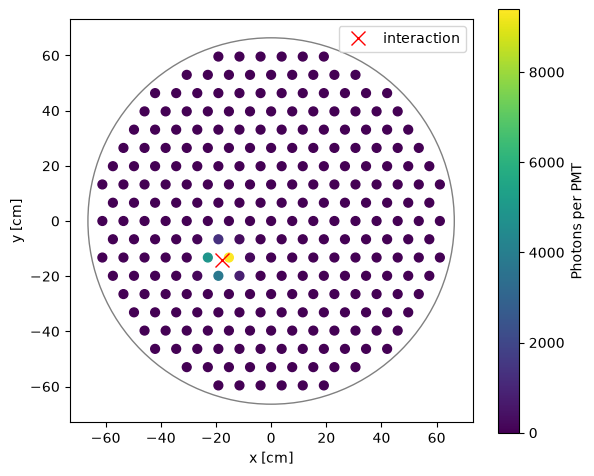

In [15]:
pmt_positions = strax.URLConfig.evaluate_dry("ember_table://pmt_positions_dummy.csv")
top_pmts = pmt_positions[pmt_positions["array"] == "top"]

one_interaction = drifted[np.argmax(drifted["n_electron_interface"])]
photons_of_interaction = s2_photons[s2_photons["cluster_id"] == one_interaction["cluster_id"]]
photons_per_channel = np.bincount(photons_of_interaction["channel"], minlength=n_tpc_pmts)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
points = ax.scatter(top_pmts["x"], top_pmts["y"], c=photons_per_channel[:n_top_pmts], s=40, cmap="viridis")
ax.plot(one_interaction["x"], one_interaction["y"], "rx", markersize=10, label="interaction")
ax.add_patch(plt.Circle((0, 0), tpc_radius, fill=False, color="gray"))
ax.set_xlabel("x [cm]")
ax.set_ylabel("y [cm]")
ax.set_aspect("equal")
ax.legend()
fig.colorbar(points, label="Photons per PMT")
plt.show()

The dummy pattern map is a Gaussian spot (σ = 5 cm) on the top array plus a uniform part, see `map_generators/dummy_s2_pattern_maps.ipynb`. A real map comes from an optical simulation or from data.

### The S2 time profile

First look at the two timing maps. Both are inverse cumulative distributions: for a uniform random number $u$ they return the delay.

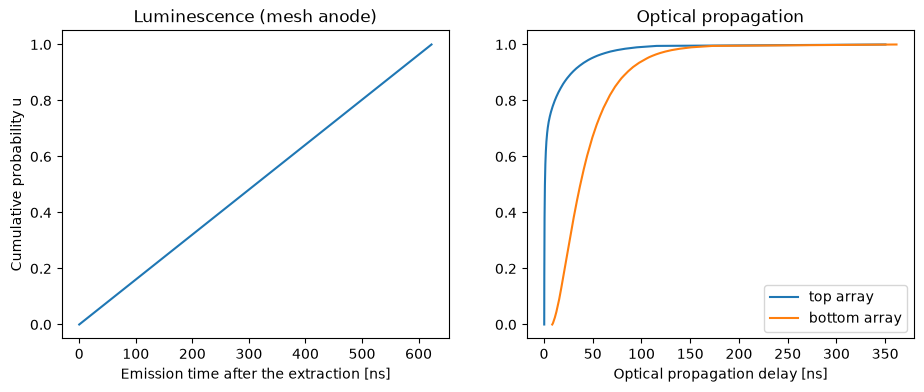

In [16]:
luminescence_map = strax.URLConfig.evaluate_dry("ember_map://s2_luminescence_timing_dummy.json?method=linear")
optical_map = strax.URLConfig.evaluate_dry("ember_map://s2_optical_propagation_dummy.json?method=linear")

u_values = np.linspace(0, 1, 200).reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(luminescence_map(u_values), u_values)
axes[0].set_xlabel("Emission time after the extraction [ns]")
axes[0].set_ylabel("Cumulative probability u")
axes[0].set_title("Luminescence (mesh anode)")
axes[1].plot(optical_map(u_values, map_name="top"), u_values, label="top array")
axes[1].plot(optical_map(u_values, map_name="bottom"), u_values, label="bottom array")
axes[1].set_xlabel("Optical propagation delay [ns]")
axes[1].set_title("Optical propagation")
axes[1].legend()
plt.show()

ember's default anode is a **mesh**: the field in the gas gap is uniform, so the light is emitted uniformly in time and the cumulative distribution is a straight line. With an anode made of **wires** the field rises close to the wires and most light is emitted at the end. `map_generators/dummy_s2_timing_maps.ipynb` builds such a map and shows its effect.

Now the S2 itself. Subtract from every photon the time of its interaction and the mean drift time. For a shallow interaction the S2 width is given by the luminescence (≈ 1 µs), for a deep one by the longitudinal diffusion:

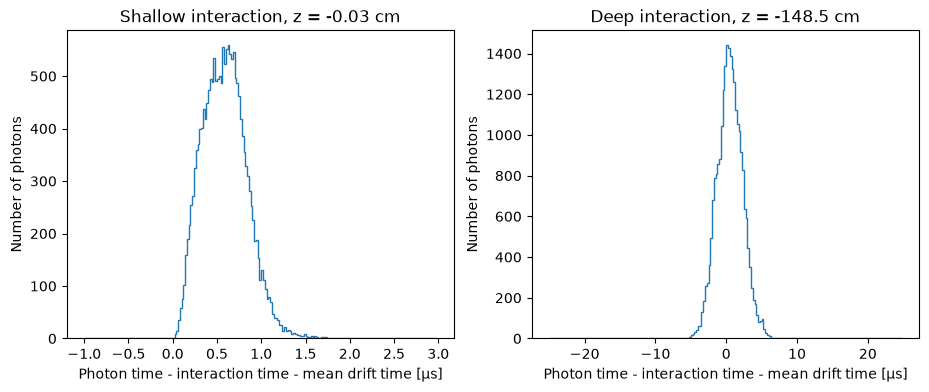

In [17]:
shallow_photons = s2_photons[s2_photons["cluster_id"] == shallow["cluster_id"]]
deep_photons = s2_photons[s2_photons["cluster_id"] == deep["cluster_id"]]

shallow_photon_time_us = (shallow_photons["time"] - shallow["time"] - shallow["drift_time_mean"]) / 1000
deep_photon_time_us = (deep_photons["time"] - deep["time"] - deep["drift_time_mean"]) / 1000

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(shallow_photon_time_us, bins=np.arange(-1, 3, 0.02), histtype="step")
axes[0].set_title(f"Shallow interaction, z = {shallow['z']:.2f} cm")
axes[1].hist(deep_photon_time_us, bins=np.arange(-25, 25, 0.25), histtype="step")
axes[1].set_title(f"Deep interaction, z = {deep['z']:.1f} cm")
for ax in axes:
    ax.set_xlabel("Photon time - interaction time - mean drift time [µs]")
    ax.set_ylabel("Number of photons")
plt.show()

### Gains and double photoelectron emission

In [18]:
print("Fraction of photons with DPE:", s2_photons["dpe"].mean(), "(p_DPE =", p_double_pe, ")")
print("Mean photon gain:", s2_photons["photon_gain"].mean())

Fraction of photons with DPE: 0.21903751349010486 (p_DPE = 0.219 )
Mean photon gain: 4195038.273541786


### The S2 of a single electron

What does the light of one extracted electron look like in time? The rows of `propagated_s2_photons` do not know which electron they belong to, so we cannot select them from the output. Instead we take the plugin itself and let it propagate the photons of one electron, with the extraction at $t = 0$.

One electron gives only about 30 photons. To see the shape of the profile we propagate 100 000 photons of the same electron as well:

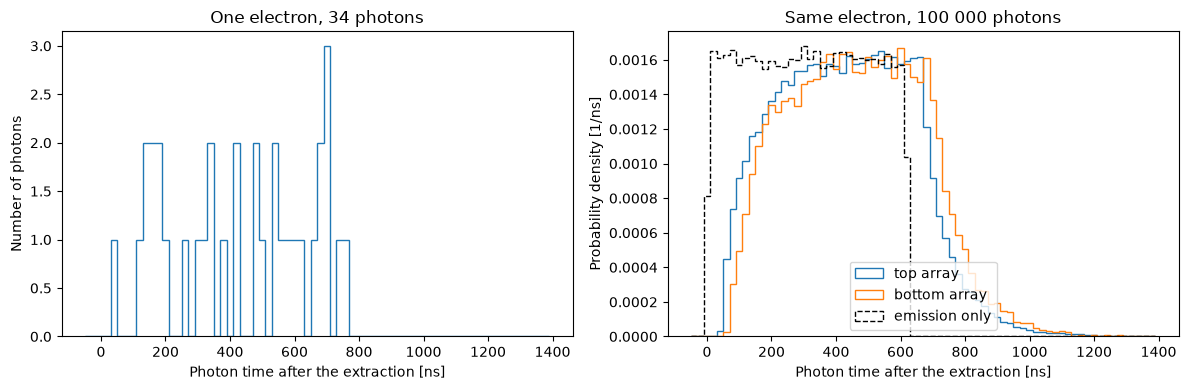

Mean photon time: top array 432 ns, bottom array 466 ns


In [19]:
photon_plugin = st.get_single_plugin(run_id, "propagated_s2_photons")

one_electron = extracted[:1].copy()
one_electron["time"] = 0
one_electron_photons = photon_plugin.propagate_photons(one_electron)

electron_with_many_photons = one_electron.copy()
electron_with_many_photons["n_s2_photons"] = 100_000
many_photons = photon_plugin.propagate_photons(electron_with_many_photons)
photon_is_top = many_photons["channel"] < n_top_pmts
emission_times = luminescence_map(np.random.random((100_000, 1)))

bins = np.arange(-50, 1400, 20)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(one_electron_photons["time"], bins=bins, histtype="step")
axes[0].set_title(f"One electron, {len(one_electron_photons)} photons")
axes[0].set_ylabel("Number of photons")
axes[1].hist(many_photons["time"][photon_is_top], bins=bins, histtype="step", density=True, label="top array")
axes[1].hist(many_photons["time"][~photon_is_top], bins=bins, histtype="step", density=True, label="bottom array")
axes[1].hist(emission_times, bins=bins, histtype="step", density=True, color="black", linestyle="--", label="emission only")
axes[1].set_title("Same electron, 100 000 photons")
axes[1].set_ylabel("Probability density [1/ns]")
axes[1].legend(loc="lower center")
for ax in axes:
    ax.set_xlabel("Photon time after the extraction [ns]")
fig.tight_layout()
plt.show()

print(f"Mean photon time: top array {many_photons['time'][photon_is_top].mean():.0f} ns, bottom array {many_photons['time'][~photon_is_top].mean():.0f} ns")

The dashed line is the emission time alone: with the mesh anode the electron emits light uniformly while it crosses the gas gap. The excimer decay (mostly the 100 ns triplet), the optical delay and the PMT transit time (≈ 46 ns) shift the profile to later times and smear its edges. The light to the bottom array travels through the whole TPC and arrives a few 10 ns later than the light to the top array.

Each S2 is the sum of such single electron profiles, shifted by the arrival times of the electrons. For a shallow interaction (section 6, left plot) the electrons arrive within a few 100 ns and the S2 looks almost like this profile; for a deep interaction the diffusion dominates.

## 7. Make it your detector: which dummy maps to replace

All maps are config options. Maps in `ember/dummy_maps` can be given by name, other files by absolute path:

```python
st.set_config({
    "field_dependencies_map": "ember_map:///path/to/my_drift_map.json?method=linear",
    "s2_pattern_map": "ember_map:///path/to/my_s2_pattern_map.pkl?method=linear",
})
```

| Dummy input | What ember assumes | Replace it with |
|---|---|---|
| drift map (`field_dependencies_map`) | constant field of 23 V/cm, NEST drift velocity and diffusion | your field map (e.g. COMSOL) → `map_generators/dummy_field_maps.ipynb` computes the drift map from it |
| survival map (`survival_probability_map`) | all electrons above the cathode survive | field-line tracking: electrons that end on the wall or below the cathode |
| S2 correction map (`s2_correction_map`) | constant 1 | measured S2 $(x, y)$ correction (relative, mean 1) |
| S2 pattern map (`s2_pattern_map`) | Gaussian spot with σ = 5 cm + uniform 15 %, AFT 0.8 | optical simulation of the S2 light, or data |
| luminescence timing (`s2_luminescence_timing_map`) | mesh anode, uniform field in the gas gap | Garfield simulation of your anode, or the wire model of `dummy_s2_timing_maps.ipynb` |
| S2 optical timing (`s2_optical_propagation_spline`) | optical toy Monte Carlo | optical simulation (e.g. Geant4) |
| detector values (`detector.yaml`) | `g2` = 30 PE, `electron_extraction_efficiency` = 0.8, lifetime 20 ms, … | your measured values |

Requirements:

* the drift map has the axes `r` and `z` and the maps `drift_speed_map` [cm/ns], `diffusion_longitudinal_map` and `diffusion_transverse_map` [cm²/ns], all **averaged** from the position up to the gate;
* the S2 pattern map has the axes `x` and `y` and one entry per channel (`n_tpc_pmts`) along its last axis;
* the timing maps have the axis `u` and are non-decreasing in `u`; the optical map has the maps `top` and `bottom`.

**Important:** strax hashes the URL, not the file content. If you overwrite a map file or a value in `detector.yaml` under the same name, strax reuses the old data. Use a new file name or delete the stored data. In the same way: **use one run id per CSV file**.

## Summary

* `ElectronDrift`: survival map, drift time from the drift map, diffusion spread, electron lifetime → electrons at the surface per interaction.
* `ElectronPropagation`: one row per electron, with arrival time and position at the surface (longitudinal and transverse diffusion).
* `ElectronExtraction`: extraction with probability $\varepsilon_\mathrm{ext}$, plus a short trapping delay.
* `SecondaryScintillation`: $N_\gamma \sim \mathrm{Poisson}(c(x, y)\, g_2 / \varepsilon_\mathrm{ext} / (1 + p_\mathrm{DPE}))$ per electron.
* `S2PhotonPropagation`: channel (pattern map), time (luminescence + excimer decay + optical delay + transit time) and gain of every photon → `propagated_s2_photons`, the input of the PMT and DAQ simulation.